# AuditAI Senado — Experimento 2: recuperação léxica × densa × híbrida (N2)

**Projeto:** AuditAI Senado: Transparência e Análise Parlamentar com IA · **Disciplina:** Inteligência Artificial (7º CC, Mackenzie) · **Prof.:** Ivan Carlos Alcântara de Oliveira

**Integrantes:** Julia Vitória Bomfim do Nascimento (10425604), William Saran dos Santos Junior (10420128)

**Histórico:** 20/11/2026 — William Saran dos Santos Junior — criação do notebook (N2).

## Objetivo
Implementar o núcleo de recuperação do agente (etapas E4 e E7 do artigo) e compará-lo em um experimento controlado: **BM25** (léxica), **busca densa** com `multilingual-e5-small` e **híbrida** por *Reciprocal Rank Fusion* (RRF). Em seguida, aplicar as "ferramentas" do agente (`buscar_trechos`, `agrupar_por_parlamentar`, `obter_evidencias`) ao melhor recuperador.

## Desenho do experimento
- **Corpus de avaliação:** amostra de 3.000 discursos (300 de cada tema + 2.400 sem nenhum dos dois temas), segmentados em trechos de até 250 palavras com sobreposição de 50 (mesma segmentação da N1).
- **Relevância:** rótulo fraco por termos do tema (como no Experimento 1). **Os termos são removidos do corpus** (com acentos preservados, para os *embeddings*), enquanto as **consultas mantêm** a linguagem natural. Assim, a busca literal não pode simplesmente "achar a palavra": o teste mede o descasamento de vocabulário.
- **Referência:** BM25 sobre o corpus **sem máscara** (teto lexical, favorecido pelos rótulos, que vêm das mesmas palavras).
- **Consultas:** 5 formulações por tema (10 no total). É um estudo piloto; o protocolo final prevê 20 a 30 perguntas com julgamento humano.
- **Pontuação do discurso:** o maior escore entre seus trechos. **Métricas:** P@10, P@50, nDCG@10, MAP (*average precision*) e MRR.

In [1]:
import sys, json, time, re, warnings, unicodedata
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from temas import TEMAS, normalizar_serie, rotular, mascarar_original
from preparacao import segmentar, normalizar_busca

SEED = 7
DIR_RES = RAIZ / "resultados" / "recuperacao"; DIR_FIG = RAIZ / "resultados" / "figuras"; DIR_CACHE = RAIZ / "data" / "cache"
for d in (DIR_RES, DIR_FIG, DIR_CACHE): d.mkdir(parents=True, exist_ok=True)
AZUL, LARANJA, VERDE, TEXTO, TEXTO2, GRADE = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#e4e3df"
mpl.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.edgecolor": TEXTO2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRADE, "axes.axisbelow": True})

## 1. Corpus de avaliação

In [2]:
df = pd.read_parquet(RAIZ / "data" / "processed" / "discursos.parquet")
df["texto_norm"] = normalizar_serie(df["texto_limpo"])
T1, T2 = list(TEMAS)
df["y1"], df["y2"] = rotular(df["texto_norm"], T1), rotular(df["texto_norm"], T2)

N_POS, N_NEG = 300, 2400
pos1 = df[df.y1 == 1].sample(N_POS, random_state=SEED)
pos2 = df[(df.y2 == 1) & ~df.codigo.isin(pos1.codigo)].sample(N_POS, random_state=SEED)
neg = df[(df.y1 == 0) & (df.y2 == 0)].sample(N_NEG, random_state=SEED)
corpus = pd.concat([pos1, pos2, neg]).sample(frac=1, random_state=SEED).reset_index(drop=True)
corpus = corpus[["codigo", "url", "ano", "autor_nome", "partido_norm", "texto_limpo", "y1", "y2"]]
print(f"{len(corpus):,} discursos | relevantes: {T1} = {corpus.y1.sum()}, {T2} = {corpus.y2.sum()} (prevalência {corpus.y1.mean():.1%} e {corpus.y2.mean():.1%})")

# versão mascarada (sem termos dos dois temas, acentos preservados)
corpus["texto_mask"] = mascarar_original(mascarar_original(corpus["texto_limpo"], T1), T2)
print("Exemplo mascarado:", corpus.loc[corpus.y1 == 1, "texto_mask"].iloc[0][:300])

3,000 discursos | relevantes: Violência contra a mulher = 303, Meio ambiente = 351 (prevalência 10.1% e 11.7%)


Exemplo mascarado: Sr. Presidente Moka, Srs. Senadores, Srªs Senadoras, Senadora Ana Amélia e os demais Senadores aqui presentes, conforme é de conhecimento de todos, na semana passada, dia 25 de novembro, comemoramos o Dia Internacional de Enfretamento à . Quem acompanhou hoje cedo o programa da Ana Maria Braga pôde 


## 2. Segmentação em trechos

In [3]:
def segmentar_corpus(coluna):
    docs, textos = [], []
    for i, t in enumerate(corpus[coluna]):
        for ch in segmentar(t, 250, 50):
            docs.append(i); textos.append(ch)
    docs = np.array(docs)
    starts = np.r_[0, np.flatnonzero(np.diff(docs)) + 1]          # trechos de um discurso são contíguos
    return docs, textos, starts

t0 = time.time()
d_m, tx_m, st_m = segmentar_corpus("texto_mask")     # corpus mascarado (experimento)
d_o, tx_o, st_o = segmentar_corpus("texto_limpo")    # corpus original (teto lexical)
print(f"trechos mascarados: {len(tx_m):,} | originais: {len(tx_o):,} ({time.time()-t0:.0f} s)")

trechos mascarados: 19,667 | originais: 19,689 (2 s)


## 3. Recuperadores
**BM25** (Okapi, `rank_bm25`, k1=1,5, b=0,75) sobre texto minúsculo, sem acentos e sem *stopwords*. **Densa:** `intfloat/multilingual-e5-small` (prefixos `query:` e `passage:` exigidos pelo modelo), vetores normalizados, similaridade por produto interno. **Híbrida:** RRF (k = 60) sobre os *rankings* de trechos do BM25 e da busca densa.

In [4]:
import nltk
try: nltk.download("stopwords", quiet=True); from nltk.corpus import stopwords; _sw = stopwords.words("portuguese")
except Exception: _sw = []
STOP = {normalizar_busca(w) for w in _sw}
def tokenizar(t): return [w for w in re.findall(r"[a-z0-9]+", normalizar_busca(t)) if len(w) > 2 and w not in STOP]

from rank_bm25 import BM25Okapi
t0 = time.time()
bm25_m = BM25Okapi([tokenizar(t) for t in tx_m], k1=1.5, b=0.75)
bm25_o = BM25Okapi([tokenizar(t) for t in tx_o], k1=1.5, b=0.75)
print(f"índices BM25 prontos ({time.time()-t0:.0f} s); stopwords: {len(STOP)}")

índices BM25 prontos (7 s); stopwords: 200


In [5]:
import torch
from sentence_transformers import SentenceTransformer
MODELO = "intfloat/multilingual-e5-small"
enc = SentenceTransformer(MODELO, device="cpu"); enc.max_seq_length = 512
# verificação do limite de entrada (512 tokens) em uma amostra de trechos
amostra_tok = np.random.default_rng(SEED).choice(len(tx_m), 500, replace=False)
n_tok = [len(enc.tokenizer("passage: " + tx_m[i])["input_ids"]) for i in amostra_tok]
print(f"tokens por trecho: mediana {np.median(n_tok):.0f}, p95 {np.percentile(n_tok, 95):.0f}, máx {max(n_tok)}; "
      f"{np.mean(np.array(n_tok) > 512):.1%} acima de 512")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokens por trecho: mediana 336, p95 384, máx 422; 0.0% acima de 512


In [6]:
arq_emb = DIR_CACHE / f"emb_e5small_{len(tx_m)}_{SEED}.npy"
if arq_emb.exists():
    EMB = np.load(arq_emb)
else:
    t0 = time.time()
    # ordena por tamanho para reduzir preenchimento (padding) nos lotes
    ordem = np.argsort([len(t) for t in tx_m])
    e = enc.encode(["passage: " + tx_m[i] for i in ordem], batch_size=32, normalize_embeddings=True,
                   show_progress_bar=False, convert_to_numpy=True)
    EMB = np.empty_like(e); EMB[ordem] = e
    np.save(arq_emb, EMB)
    print(f"embeddings calculados em {(time.time()-t0)/60:.1f} min")
print("matriz de embeddings:", EMB.shape)

matriz de embeddings: (19667, 384)


## 4. Consultas, escores e métricas

In [7]:
CONSULTAS = {
    T1: ["violência contra a mulher", "feminicídio e agressão a mulheres", "mulheres vítimas de violência doméstica",
         "lei Maria da Penha e medidas de proteção às mulheres", "combate à violência de gênero"],
    T2: ["meio ambiente", "desmatamento e queimadas na Amazônia", "mudanças climáticas e aquecimento global",
         "preservação ambiental e desenvolvimento sustentável", "proteção do meio ambiente e legislação ambiental"],
}
RELEV = {T1: corpus.y1.to_numpy().astype(bool), T2: corpus.y2.to_numpy().astype(bool)}

def escores_doc(s_trecho, starts):
    return np.maximum.reduceat(s_trecho, starts)          # escore do discurso = melhor trecho

def rrf(*escores, k=60):
    out = np.zeros(len(escores[0]))
    for s in escores:
        pos = np.empty(len(s), dtype=int); pos[np.argsort(-s)] = np.arange(len(s))
        out += 1.0 / (k + pos + 1)
    return out

def s_bm25(idx, consulta): return idx.get_scores(tokenizar(consulta))
def s_dens(consulta): return EMB @ enc.encode("query: " + consulta, normalize_embeddings=True)

def ranquear(consulta):
    b, d = s_bm25(bm25_m, consulta), s_dens(consulta)
    return {"BM25 (corpus mascarado)": escores_doc(b, st_m),
            "Densa (E5-small)": escores_doc(d, st_m),
            "Híbrida RRF": escores_doc(rrf(b, d), st_m),
            "BM25 sem máscara (teto lexical)": escores_doc(s_bm25(bm25_o, consulta), st_o)}

def metricas(escore, rel):
    ordem = np.argsort(-escore, kind="stable"); r = rel[ordem]; R = r.sum()
    p = lambda k: r[:k].mean()
    dcg = (r[:10] / np.log2(np.arange(2, 12))).sum(); idcg = (1 / np.log2(np.arange(2, min(R, 10) + 2))).sum()
    ap = (np.cumsum(r)[r] / (np.flatnonzero(r) + 1)).sum() / R
    primeiro = np.flatnonzero(r)[0] + 1
    return {"P@10": p(10), "P@50": p(50), "nDCG@10": dcg / idcg, "MAP": ap, "MRR": 1 / primeiro}

linhas = []
for tema, qs in CONSULTAS.items():
    for q in qs:
        for metodo, s in ranquear(q).items():
            linhas.append({"tema": tema, "consulta": q, "metodo": metodo, **metricas(s, RELEV[tema])})
res = pd.DataFrame(linhas)
res.to_csv(DIR_RES / "recuperacao_por_consulta.csv", index=False)
print(f"{len(res)} avaliações ({res.consulta.nunique()} consultas × {res.metodo.nunique()} métodos)")

40 avaliações (10 consultas × 4 métodos)


### Resultados (média das 5 consultas de cada tema)

In [8]:
ORDEM = ["BM25 (corpus mascarado)", "Densa (E5-small)", "Híbrida RRF", "BM25 sem máscara (teto lexical)"]
met = ["P@10", "P@50", "nDCG@10", "MAP", "MRR"]
tab = res.groupby(["tema", "metodo"])[met].mean().reindex(pd.MultiIndex.from_product([list(TEMAS), ORDEM]))
tab.round(3).to_csv(DIR_RES / "recuperacao_resumo.csv")
tab.round(3)

P@10   P@50  \
Violência contra a mulher BM25 (corpus mascarado)          0.98  0.876   
                          Densa (E5-small)                 0.98  0.964   
                          Híbrida RRF                      0.98  0.980   
                          BM25 sem máscara (teto lexical)  1.00  0.984   
Meio ambiente             BM25 (corpus mascarado)          0.54  0.496   
                          Densa (E5-small)                 0.98  0.712   
                          Híbrida RRF                      0.82  0.628   
                          BM25 sem máscara (teto lexical)  0.96  0.924   

                                                           nDCG@10    MAP  \
Violência contra a mulher BM25 (corpus mascarado)            0.987  0.617   
                          Densa (E5-small)                   0.983  0.728   
                          Híbrida RRF                        0.986  0.715   
                          BM25 sem máscara (teto lexical)    1.000  0.749   
Meio ambiente             BM25 (corpus mascarado)            0.550  0.273   
                          Densa (E5-small)                   0.984  0.430   
                          Híbrida RRF                        0.857  0.382   
                          BM25 sem máscara (teto lexical)    0.942  0.548   

                                                             MRR  
Violência contra a mulher BM25 (corpus mascarado)          1.000  
                          Densa (E5-small)                 1.000  
                          Híbrida RRF                      1.000  
                          BM25 sem máscara (teto lexical)  1.000  
Meio ambiente             BM25 (corpus mascarado)          0.733  
                          Densa (E5-small)                 1.000  
                          Híbrida RRF                      1.000  
                          BM25 sem máscara (teto lexical)  0.900

In [9]:
geral = res.groupby("metodo")[met].agg(["mean", "std"]).reindex(ORDEM)
print("Média geral (10 consultas) e desvio-padrão:"); geral.round(3)

Média geral (10 consultas) e desvio-padrão:


P@10          P@50        nDCG@10         \
                                 mean    std   mean    std    mean    std   
metodo                                                                      
BM25 (corpus mascarado)          0.76  0.284  0.686  0.270   0.769  0.280   
Densa (E5-small)                 0.98  0.042  0.838  0.140   0.984  0.035   
Híbrida RRF                      0.90  0.125  0.804  0.219   0.921  0.092   
BM25 sem máscara (teto lexical)  0.98  0.063  0.954  0.054   0.971  0.092   

                                   MAP           MRR         
                                  mean    std   mean    std  
metodo                                                       
BM25 (corpus mascarado)          0.445  0.206  0.867  0.292  
Densa (E5-small)                 0.579  0.163  1.000  0.000  
Híbrida RRF                      0.548  0.187  1.000  0.000  
BM25 sem máscara (teto lexical)  0.649  0.180  0.950  0.158

In [10]:
# Diferenças pareadas por consulta (Densa e Híbrida contra BM25 mascarado): quantas consultas cada método vence
p = res.pivot_table(index=["tema", "consulta"], columns="metodo", values="nDCG@10")
for m in ["Densa (E5-small)", "Híbrida RRF"]:
    d = p[m] - p["BM25 (corpus mascarado)"]
    print(f"{m} - BM25 mascarado em nDCG@10: média {d.mean():+.3f}; vence em {(d > 0).sum()} de {len(d)} consultas")

Densa (E5-small) - BM25 mascarado em nDCG@10: média +0.215; vence em 6 de 10 consultas
Híbrida RRF - BM25 mascarado em nDCG@10: média +0.153; vence em 6 de 10 consultas


## 5. Figura

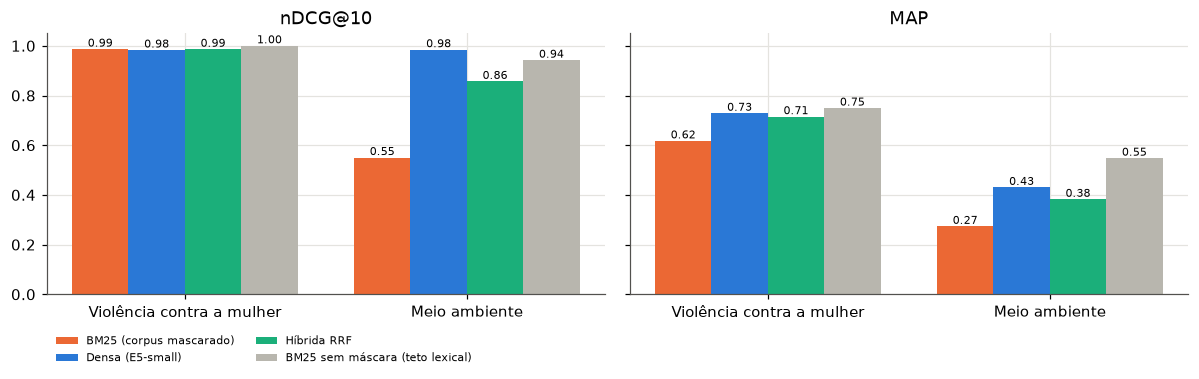

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
cores = [LARANJA, AZUL, VERDE, "#b8b6ae"]
for ax, m in zip(axs, ["nDCG@10", "MAP"]):
    x = np.arange(len(TEMAS)); w = 0.2
    for i, (metodo, cor) in enumerate(zip(ORDEM, cores)):
        v = [tab.loc[(t, metodo), m] for t in TEMAS]
        ax.bar(x + (i - 1.5) * w, v, w, color=cor, label=metodo)
        for xx, vv in zip(x + (i - 1.5) * w, v): ax.text(xx, vv + 0.01, f"{vv:.2f}", ha="center", fontsize=7)
    ax.set_xticks(x); ax.set_xticklabels(list(TEMAS)); ax.set_title(m); ax.set_ylim(0, 1.05)
axs[0].legend(frameon=False, fontsize=7, loc="upper left", bbox_to_anchor=(0, -0.12), ncol=2)
fig.tight_layout(); fig.savefig(DIR_FIG / "fig6_recuperacao.png"); fig.savefig(DIR_FIG / "fig6_recuperacao.pdf"); plt.show()

## 6. Ferramentas do agente aplicadas ao melhor recuperador
`buscar_trechos` devolve os discursos mais relevantes (com o trecho de maior escore como evidência), `agrupar_por_parlamentar` conta discursos e proporção por autor, e `obter_evidencias` seleciona os trechos citáveis, com a URL oficial. Neste experimento as ferramentas são acionadas diretamente; a camada de LLM que interpreta a pergunta e redige a resposta (E5) é a próxima etapa.

In [12]:
corpus["autor_n_corpus"] = corpus.groupby("autor_nome")["codigo"].transform("size")

def buscar_trechos(consulta, k=50, metodo="Híbrida RRF"):
    b, d = s_bm25(bm25_m, consulta), s_dens(consulta)
    s_trecho = {"BM25 (corpus mascarado)": b, "Densa (E5-small)": d, "Híbrida RRF": rrf(b, d)}[metodo]
    esc_doc = escores_doc(s_trecho, st_m)
    top = np.argsort(-esc_doc)[:k]
    melhor_trecho = {}
    for di in top:
        i0 = st_m[di]; i1 = st_m[di + 1] if di + 1 < len(st_m) else len(tx_m)
        melhor_trecho[di] = i0 + int(np.argmax(s_trecho[i0:i1]))
    return [(int(di), float(esc_doc[di]), int(melhor_trecho[di])) for di in top]

def agrupar_por_parlamentar(resultados):
    d = corpus.iloc[[r[0] for r in resultados]]
    g = d.groupby("autor_nome").agg(discursos=("codigo", "size"), partido=("partido_norm", "last"))
    tot = corpus.groupby("autor_nome").size()
    g["total_no_corpus"] = tot.reindex(g.index).values; g["proporcao"] = (g.discursos / g.total_no_corpus).round(2)
    return g.sort_values(["discursos", "proporcao"], ascending=False)

def obter_evidencias(resultados, autor, n=2):
    saida = []
    for di, esc, ti in resultados:
        if corpus.autor_nome.iloc[di] == autor:
            saida.append((corpus.ano.iloc[di], corpus.url.iloc[di], tx_m[ti][:300].replace("\n", " ")))
    return saida[:n]

consulta = "Quais parlamentares mais abordaram violência contra a mulher?"
res_busca = buscar_trechos("violência contra a mulher", k=50)
rel_top = RELEV[T1][[r[0] for r in res_busca]].mean()
print(f"Consulta: {consulta}\nPrecisão nos 50 primeiros (rótulo fraco): {rel_top:.0%}")
ranking = agrupar_por_parlamentar(res_busca); ranking.head(8)

Consulta: Quais parlamentares mais abordaram violência contra a mulher?
Precisão nos 50 primeiros (rótulo fraco): 100%


,discursos,partido,total_no_corpus,proporcao
autor_nome,,,,
ana rita,5,PT,19,0.26
paulo paim,4,PT,119,0.03
marta suplicy,3,PT,8,0.38
rose de freitas,3,PMDB,17,0.18
gleisi hoffmann,3,PT,20,0.15
serys slhessarenko,3,PT,22,0.14
lidice da mata,3,PSB,23,0.13
lucio alcantara,3,PSDB,24,0.12


In [13]:
autor = ranking.index[0]
print("Evidências para", autor)
for ano, url, trecho in obter_evidencias(res_busca, autor):
    print(f"- ({ano}) {url}\n  {trecho}...")

Evidências para ana rita
- (2014) https://www25.senado.leg.br/web/atividade/pronunciamentos/-/p/texto/409178
  Srªs Senadoras, Srs. Senadores, são dados alarmantes. Sem que a lei seja tomada como uma política de Estado, continuaremos a ter problemas. Só iremos superá-los, se, efetivamente, a legislação for assumida por todas e todos. Se não criarmos mecanismos eficientes, para colocá-la em prática, a legisla...
- (2014) https://www25.senado.leg.br/web/atividade/pronunciamentos/-/p/texto/410031
  As agressões físicas, que não deixam de ser também uma violência psicológica, ainda são a principal forma de manifestação direta da discriminação contra a mulher, aliada à discriminação velada ou nem tanto, que teima em colocar a mulher em situação de inferioridade em relação aos homens. A é uma vio...


In [14]:
# Comparação com a linha de base léxica da N1 (contagem de menções): sobreposição entre os parlamentares do topo
lex = corpus[corpus.y1 == 1].groupby("autor_nome").size().sort_values(ascending=False).head(8)
print("Linha de base léxica (rótulo fraco, amostra):", list(lex.index))
print("Híbrida (mascarado), top 8:", list(ranking.head(8).index))
print("Interseção:", len(set(lex.index) & set(ranking.head(8).index)), "de 8")

Linha de base léxica (rótulo fraco, amostra): ['paulo paim', 'ana rita', 'regina sousa', 'angela portela', 'vanessa grazziotin', 'rose de freitas', 'serys slhessarenko', 'renan calheiros']
Híbrida (mascarado), top 8: ['ana rita', 'paulo paim', 'marta suplicy', 'rose de freitas', 'gleisi hoffmann', 'serys slhessarenko', 'lidice da mata', 'lucio alcantara']
Interseção: 4 de 8
